STAGE 1

In [47]:
import pandas as pd
import numpy as np

# Load the dataset using sep='\t' to specify tab-separated values and header=None since the dataset does not have a header row.
df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'message'])

# Display the first 5 rows
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [48]:
# used basic functions to explore the dataset and check for missing values, duplicates, and the distribution of the target variable.
print("1. Dataset Shape (Rows, Columns):", df.shape)

print("2. Missing Values per Column:\n", df.isnull().sum())

print("3. Total Duplicate Rows:", df.duplicated().sum())

print("4. Target Variable Distribution (Counts):\n", df['label'].value_counts())

print("5. Target Variable Distribution (Percentages %):\n", (df['label'].value_counts(normalize=True) * 100).round(2))

print("6. Dataset Info:")
df.info()

1. Dataset Shape (Rows, Columns): (5572, 2)
2. Missing Values per Column:
 label      0
message    0
dtype: int64
3. Total Duplicate Rows: 403
4. Target Variable Distribution (Counts):
 label
ham     4825
spam     747
Name: count, dtype: int64
5. Target Variable Distribution (Percentages %):
 label
ham     86.59
spam    13.41
Name: proportion, dtype: float64
6. Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


1.1 Dataset Understanding and Description:
-First loaded the data useing pd.read_csv in pandas using the parameter because the dataset is not speatead with comma
- The SMS Spam Collection dataset has two attributes and 5,572 messages.  
- There is no missing data in the dataset. There are 403 duplicate rows.  
- `label` (Target Variable): A categorical variable with two classes that indicate the legitimacy of the message. `ham`: 4,825 legitimate messages, and `spam`: 747 unsolicited messages.  
- `message` (Feature): An unstructured text attribute containing the raw SMS content.  
- The dataset has a significant class imbalance in the labels, with 4,825 (86.59%) messages classified as ham and 747 (13.41%) classified as spam.

In [49]:
#Remove duplicate rows and reset index
df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)

# Check for inconsistent whitespace-only messages
df_clean['message'] = df_clean['message'].str.strip()
# to check for empty messages after stripping whitespace
empty_msgs = (df_clean['message'] == '').sum()

df_clean['char_length'] = df_clean['message'].apply(len)
df_clean['word_count'] = df_clean['message'].apply(lambda x: len(x.split()))

print("1. Shape After Removing Duplicates:", df_clean.shape)
print("2. Empty Messages Found:", empty_msgs)
print("3. Target Distribution After Cleaning:\n", df_clean['label'].value_counts())
print("4. Target Percentages After Cleaning (%):\n", (df_clean['label'].value_counts(normalize=True) * 100).round(2))
print("5. Summary Statistics for Message :\n", df_clean[['char_length', 'word_count']].describe().round(2))

1. Shape After Removing Duplicates: (5169, 4)
2. Empty Messages Found: 0
3. Target Distribution After Cleaning:
 label
ham     4516
spam     653
Name: count, dtype: int64
4. Target Percentages After Cleaning (%):
 label
ham     87.37
spam    12.63
Name: proportion, dtype: float64
5. Summary Statistics for Message :
        char_length  word_count
count      5169.00     5169.00
mean         79.31       15.44
std          58.43       11.12
min           2.00        1.00
25%          36.00        7.00
50%          61.00       12.00
75%         118.00       22.00
max         910.00      171.00


1.2 Handling Missing Values, Duplicates, Inconsistent Data, and Outliers:
there are no null values or empty white spaces, stripped text is used to ensure data consistency

403 duplicate records were removed using drop_duplicates, reducing the dataset from 5,572 to 5,169 unique messages, the dataset contains 4,516 ham messages which about (87.37%) and 653 spam messages (12.63%).
Why: The importance of removing duplicate data to prevent data leakage in the training, validation and test set that will affect the accuracy because the model will memorize the repeated spam.

Creating new cols char_length and word_count to extract structural meta data from the message column , so the model be able to identify pattern in the message length to identify when it spam or ham
 Why: In SMS text classification, extreme lengths represent genuine user behavior, for example short replies like "Ok" vs. lengthy promotional texts. rather than data corruption. So, these records were retained to preserve real-world variance, and their numerical scale differences will be mitigated via feature scaling.   



In [50]:
import string
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 1. Target Encoding to turn  ham -> 0, spam -> 1
df_clean['label_encoded'] = df_clean['label'].map({'ham': 0, 'spam': 1})

# 2. Feature Engineering: Extract domain-specific numerical features
df_clean['digit_count'] = df_clean['message'].apply(lambda x: sum(c.isdigit() for c in x))
df_clean['uppercase_count'] = df_clean['message'].apply(lambda x: sum(c.isupper() for c in x))
df_clean['special_char_count'] = df_clean['message'].apply(lambda x: sum(c in string.punctuation or c in '£€$' for c in x))

# 3. Text Preprocessing (Lowercase, remove punctuation/numbers, remove stopwords)
def preprocess_text(text):
    text = text.lower()
    text = ''.join([c for c in text if c not in string.punctuation and not c.isdigit() and c not in '£€$'])
    words = [word for word in text.split() if word not in ENGLISH_STOP_WORDS]
    return ' '.join(words)

df_clean['clean_message'] = df_clean['message'].apply(preprocess_text)

# Compare mean values of engineered features between Ham (0) and Spam (1)
print("Mean Feature Values by Class (0 = Ham, 1 = Spam):")
display(df_clean.groupby('label')[['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count']].mean().round(2))

# Display first 5 rows with new engineered columns
df_clean[['label', 'label_encoded', 'char_length', 'digit_count', 'uppercase_count', 'clean_message']].head()

Mean Feature Values by Class (0 = Ham, 1 = Spam):


,char_length,word_count,digit_count,uppercase_count,special_char_count
label,,,,,
ham,70.87,14.24,0.30,3.98,3.83
spam,137.66,23.74,15.49,15.27,6.05


,label,label_encoded,char_length,digit_count,uppercase_count,clean_message
0,ham,0,111,0,3,jurong point crazy available bugis n great wor...
1,ham,0,29,0,2,ok lar joking wif u oni
2,spam,1,155,25,10,free entry wkly comp win fa cup final tkts st ...
3,ham,0,49,0,2,u dun say early hor u c say
4,ham,0,61,0,2,nah dont think goes usf lives


1.3 Encoding, Text Preprocessing, and Feature Engineering:
Target Encoding: The categorical target variable label it was  binary-encoded into label_encoded (ham -->0, spam -->1) to make it compatible with mathematical optimization in machine-learning classifiers and neural networks.
   
Domain-Specific Feature Engineering: Five structural meta-features were engineered from the raw text prior to cleaning: char_length, word_count, digit_count, uppercase_count, and special_char_count.
why: Group-level mean analysis revealed drastic behavioral differences between classes , spam messages average 15.49 digits, 15.27 uppercase letters, and 137.66 characters, compared to just 0.30 digits, 3.98 uppercase letters, and 70.87 characters in ham messages. Preserving these structural indicators before stripping punctuation and numbers ensures critical discriminative signals are not lost.

In text Preprocessing,To prepare the unstructured text for TF-IDF vectorization, a clean_message attribute was generated by converting characters to lowercase, removing punctuation, currency symbols, and digits, and filtering out standard English stopwords.
why: This reduces vocabulary noise and dimensionality while retaining core semantic tokens




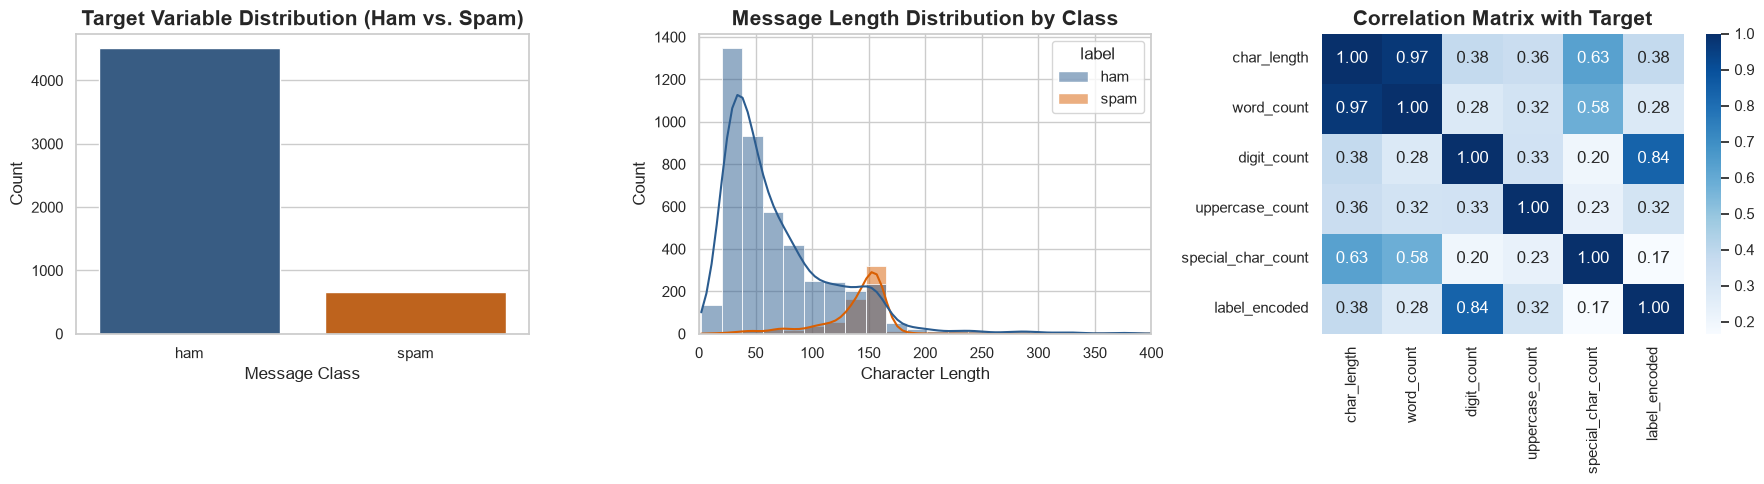

Feature Relevance (Correlation with Target 'label_encoded'):
digit_count           0.8369
char_length           0.3798
uppercase_count       0.3184
word_count            0.2839
special_char_count    0.1661
Name: label_encoded, dtype: float64


In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# This step for style setup
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1 Target Class Distribution
sns.countplot(data=df_clean, x='label', hue='label', palette=['#2b5c8f', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Target Variable Distribution (Ham vs. Spam)', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Message Class')
axes[0].set_ylabel('Count')

# Plot 2: Character Length Distribution by Class
sns.histplot(data=df_clean, x='char_length', hue='label', bins=50, kde=True, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Message Length Distribution by Class', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Character Length')
axes[1].set_xlim(0, 400)

# Plot 3: Correlation Heatmap of Engineered Features with Target
engineered_cols = ['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count', 'label_encoded']
corr_matrix = df_clean[engineered_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', ax=axes[2])
axes[2].set_title('Correlation Matrix with Target', fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

# Print exact correlation ranking with target variable
print("Feature Relevance (Correlation with Target 'label_encoded'):")
print(corr_matrix['label_encoded'].drop('label_encoded').sort_values(ascending=False).round(4))

1.4 Exploratory Data Analysis (EDA) and Feature Relevance: Target Distribution Analysis:
 Visualizing the target variable confirms a severe class imbalance (87.37% ham vs. 12.63% spam). Accuracy alone is not enough for model evaluation; stratified data splitting and metrics such as Precision, Recall, F1-score, and ROC-AUC will be prioritized in later stages.
 Behavioral Length Patterns: The character length distribution reveals a bimodal separation between classes. Legitimate ham messages follow a right-skewed distribution concentrated between 20 and 80 characters, whereas spam messages cluster sharply near 140–160 characters (the standard single-SMS character limit used by marketers to maximize promotional content).   
To identifying the Most Relevant Features: Pearson correlation analysis against label_encoded ranks the engineered features in the following order of predictive relevance:
digit_count (r = 0.8369): The strongest structural predictor of spam, reflecting phone numbers, prize claims, and text-back shortcodes.
char_length (r = 0.3798): Moderate positive correlation means that longer messages are more likely to be spam.
uppercase_count (r = 0.3184): Captures aggressive promotional capitalization.
word_count (r = 0.2839) and special_char_count (r = 0.1661).
therefore, there is  a high collinearity of r = 0.97 between char_length and word_count).   



STAGE 2


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

# Define features (X) and target (y)
num_cols = ['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count']
X = df_clean[['clean_message'] + num_cols]
y = df_clean['label_encoded']

# Step 1: Split into 70% Training and 30% Temporary (Validation + Test) using Stratified Sampling
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 2: Split the 30% Temporary set equally into 15% Validation and 15% Test
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Step 3: Apply TF-IDF Vectorization on text (Fit ONLY on Training set to prevent data leakage)
tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train_raw['clean_message'])
X_val_tfidf = tfidf.transform(X_val_raw['clean_message'])
X_test_tfidf = tfidf.transform(X_test_raw['clean_message'])

# Step 4: Apply StandardScaler on numerical engineered features (Fit ONLY on Training set)
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_raw[num_cols])
X_val_num = scaler.transform(X_val_raw[num_cols])
X_test_num = scaler.transform(X_test_raw[num_cols])

# Step 5: Combine TF-IDF features and Scaled numerical features into final matrices
X_train = hstack([X_train_tfidf, X_train_num]).tocsr()
X_val = hstack([X_val_tfidf, X_val_num]).tocsr()
X_test = hstack([X_test_tfidf, X_test_num]).tocsr()

# Print summary of splits to verify shapes and stratification
print(f"Training Set   (70%): {X_train.shape[0]} samples | Spam Ratio: {(y_train.mean()*100):.2f}% | Matrix Shape: {X_train.shape}")
print(f"Validation Set (15%): {X_val.shape[0]} samples  | Spam Ratio: {(y_val.mean()*100):.2f}% | Matrix Shape: {X_val.shape}")
print(f"Test Set       (15%): {X_test.shape[0]} samples  | Spam Ratio: {(y_test.mean()*100):.2f}% | Matrix Shape: {X_test.shape}")

Training Set   (70%): 3618 samples | Spam Ratio: 12.63% | Matrix Shape: (3618, 3005)
Validation Set (15%): 775 samples  | Spam Ratio: 12.65% | Matrix Shape: (775, 3005)
Test Set       (15%): 776 samples  | Spam Ratio: 12.63% | Matrix Shape: (776, 3005)


2. Feature Vectorization and Scaling (Preventing Data Leakage):
The cleaned dataset contained 5,169 records. It was divided into training, validation and test sets using a stratified 70% / 15% / 15% split with random_state=42.

Training Set (70%)
•	Records: 3,618
•	Spam Proportion: 12.63%
•	Purpose: Train the models.
Validation Set (15%)
•	Records: 775
•	Spam Proportion: 12.65%
•	Purpose: Tune hyperparameters and check for underfitting or overfitting.
Test Set (15%)
•	Records: 776
•	Spam Proportion: 12.63%
•	Purpose: Evaluate and compare the final models on unseen data.


This split kept most records for training while leaving separate sets for tuning and final evaluation. Stratification maintained approximately the same spam proportion across all three sets. The validation and test sets each contained about 98 spam messages.
After splitting the data, the text vectorizer and numerical scaler were fitted only on the training set using fit_transform. They were then applied to the validation and test sets using transform. This kept information from the evaluation sets out of preprocessing decisions.
The clean_message column was converted into numerical features using TfidfVectorizer(max_features=3000). TF-IDF gives less weight to words that appear in many messages. Limiting the vocabulary to 3,000 features reduced storage and processing requirements.
The five numerical features—char_length, word_count, digit_count, uppercase_count and special_char_count—were scaled using StandardScaler. The scaler used the training data’s statistics to give each feature a mean of 0 and a standard deviation of 1 on that set. Scaling helps models such as Neural Networks, Logistic Regression and SVMs handle features measured on different scales.
The scaled numerical features were combined with the TF-IDF matrix, producing 3,005 features per record.



STAGE 3

3.1 Model Selection Criteria:

The choice of models in this stage is based on the characteristics of the data prepared in Stages 1 and 2:
- **Problem type:** binary classification (ham = 0, spam = 1), so only classification models are used.
- **Many features:** each message is represented by 3,005 features (3,000 TF-IDF word features + 5 scaled numerical features), and most TF-IDF values are zero.
- **Small dataset:** only 3,618 training samples, which is small compared to the number of features. This raises the risk of overfitting for very complex models.
- **Class imbalance:** spam is only about 12.6% of the data. A model that always predicts ham would still reach about 87% accuracy, so all models use class weighting and are compared mainly with Precision, Recall and F1-score.

Based on these points, four models were developed: three traditional models (Logistic Regression, Linear SVM and Random Forest) and the mandatory Neural Network. All models are trained on the training set and checked on the validation set only. The test set is not used in this stage and is kept for the final evaluation in Stage 5. A fixed random seed (42), the same one used in Stage 2, makes all results reproducible.

In [53]:
import time
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fix all random seeds so every group member gets the same results
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Inputs come directly from Stage 2 (no new split is made here)
print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print("Spam in training set:", int(y_train.sum()), "of", len(y_train))

X_train: (3618, 3005) | X_val: (775, 3005)
Spam in training set: 457 of 3618


In [54]:
# Helper used for every model: scores on the training AND validation sets.
# The test set is NOT used here. It is kept for the final evaluation in Stage 5.
def evaluate_model(name, y_tr_true, y_tr_pred, y_va_true, y_va_pred, train_time):
    return {
        'Model': name,
        'Train F1': f1_score(y_tr_true, y_tr_pred),
        'Val Accuracy': accuracy_score(y_va_true, y_va_pred),
        'Val Precision': precision_score(y_va_true, y_va_pred, zero_division=0),
        'Val Recall': recall_score(y_va_true, y_va_pred),
        'Val F1': f1_score(y_va_true, y_va_pred),
        'Train Time (s)': train_time,
    }

results = []

We wrote a small function called evaluate_model to measure all the models in the same way. It calculates the F1-score on the training set and the scores on the validation set. If the training score is much higher than the validation score, this means overfitting, and if both are low, this means underfitting.

3.2 Model 1: Logistic Regression

**Why we chose it:**
- It is a simple linear model and it usually works very well with text data. Spam messages use clear words like "free", "win" and "claim", so a straight line can separate most spam from ham.
- It is very fast even with a large number of features. We used the liblinear solver because it works well with this type of data.
- It gives probabilities, which we will need for ROC-AUC in Stage 5.
- It is easy to understand, because every feature gets a weight that shows if it pushes the message toward spam or ham.
- We used class_weight='balanced' so the model gives more importance to the spam messages.

In [55]:
# Model 1: Logistic Regression
start = time.time()
log_reg = LogisticRegression(
    solver='liblinear',        # efficient for sparse, high-dimensional data
    class_weight='balanced',   # gives more weight to the minority spam class
    max_iter=1000,
    random_state=SEED
)
log_reg.fit(X_train, y_train)
lr_time = time.time() - start

results.append(evaluate_model('Logistic Regression',
                              y_train, log_reg.predict(X_train),
                              y_val, log_reg.predict(X_val), lr_time))
pd.DataFrame(results[-1:]).round(4)

,Model,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Train Time (s)
0,Logistic Regression,0.9507,0.9768,0.9082,0.9082,0.9082,0.0208


In [56]:
# Words with the largest positive coefficients push a message towards spam
feature_names = list(tfidf.get_feature_names_out()) + num_cols
coefs = pd.Series(log_reg.coef_[0], index=feature_names)
print("Top 15 features pushing a message towards SPAM:")
print(coefs.sort_values(ascending=False).head(15).round(3))

Top 15 features pushing a message towards SPAM:
digit_count    3.722
char_length    3.265
free           2.944
mobile         2.629
reply          2.318
text           2.151
real           1.924
brought        1.921
enjoy          1.848
arsenal        1.824
sexy           1.795
message        1.791
ringtone       1.778
weeks          1.742
content        1.725
dtype: float64


When we looked at the top weights, digit_count and char_length came first. These are the same features that had the highest correlation with spam in Stage 1. After them came words like "free", "mobile", "reply", "text" and "ringtone". This shows that adding the numerical features to TF-IDF was a good decision.

3.3 Model 2: Support Vector Machine (Linear Kernel)

**Why we chose it:**
- SVM tries to find the line that separates the two classes with the biggest margin. It works well when there are many features, like our 3,005 features.
- We used a linear kernel and not RBF, because text data can usually be separated with a straight line, and it is much faster. LinearSVC is the scikit-learn version made for this case.
- We kept C=1.0 (the default) as a starting value. The best value will be found in Stage 4.
- We also used class_weight='balanced' for the same reason as Logistic Regression.

In [57]:
# Model 2: Support Vector Machine (linear kernel)
start = time.time()
svm_clf = LinearSVC(
    C=1.0,
    class_weight='balanced',
    max_iter=5000,
    random_state=SEED
)
svm_clf.fit(X_train, y_train)
svm_time = time.time() - start

results.append(evaluate_model('SVM (Linear)',
                              y_train, svm_clf.predict(X_train),
                              y_val, svm_clf.predict(X_val), svm_time))
pd.DataFrame(results[-1:]).round(4)

,Model,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Train Time (s)
0,SVM (Linear),0.9978,0.9845,0.93,0.949,0.9394,0.0522


3.4 Model 3: Random Forest (Ensemble Learning)

**Why we chose it:**
- Random Forest combines many decision trees. Each tree learns from a random part of the data, and the final answer is the majority vote. This makes it more stable than a single decision tree.
- It is a non-linear model, so it can find patterns that combine features, for example a long message that also has many digits.
- It shows which features are the most important, so we can compare it with the correlation results from Stage 1.
- It is a different type of model from the linear ones, so our comparison includes linear models, tree models and a neural network.
- We started with 200 trees, class_weight='balanced' and no limit on the tree depth.

In [58]:
# Model 3: Random Forest (ensemble of decision trees)
start = time.time()
rf_clf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    n_jobs=-1,
    random_state=SEED
)
rf_clf.fit(X_train, y_train)
rf_time = time.time() - start

results.append(evaluate_model('Random Forest',
                              y_train, rf_clf.predict(X_train),
                              y_val, rf_clf.predict(X_val), rf_time))

# Most important features according to the forest
rf_importance = pd.Series(rf_clf.feature_importances_, index=feature_names)
print("Top 10 features used by Random Forest:")
print(rf_importance.sort_values(ascending=False).head(10).round(4))
pd.DataFrame(results[-1:]).round(4)

Top 10 features used by Random Forest:
digit_count           0.2023
uppercase_count       0.1150
char_length           0.0771
word_count            0.0516
special_char_count    0.0275
free                  0.0178
txt                   0.0159
mobile                0.0157
claim                 0.0140
reply                 0.0117
dtype: float64


,Model,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Train Time (s)
0,Random Forest,0.9989,0.9819,0.9375,0.9184,0.9278,0.8187


In the feature importance results, the engineered numerical features like digit_count were at the top of the list, together with words like "free" and "mobile".

3.5 Model 4: Neural Network

**Why we chose it:**
- A neural network can learn more complex (non-linear) patterns between the words and the numerical features that the linear models cannot find.
- We used a simple fully connected network (MLP), because each message is already a fixed list of 3,005 numbers from Stage 2.
- The numerical features were already scaled in Stage 2, which helps the network learn in a stable way.

**Network structure:**
- Input layer: 3,005 features.
- Two hidden layers: 64 neurons and then 32 neurons, both with ReLU activation. We kept the network small because we only have 3,618 training messages, and a bigger network would overfit.
- Dropout (0.5 and 0.25): randomly turns off some neurons while training to reduce overfitting.
- Output layer: 1 neuron with sigmoid, which gives the probability that the message is spam.
- Loss function: binary cross-entropy, because this is a binary classification problem.
- Optimizer: Adam with a learning rate of 0.001.
- We built it with Keras (TensorFlow) because it saves the training and validation loss for every epoch.

In [59]:
# Model 4: Neural Network (mandatory) - a fully connected network (MLP) built with Keras
# Keras needs dense input, so the sparse matrices from Stage 2 are converted.
X_train_dense = X_train.toarray().astype('float32')
X_val_dense = X_val.toarray().astype('float32')

def build_neural_network(input_dim, units_1=64, units_2=32, dropout_rate=0.5, learning_rate=0.001):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(units_1, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(units_2, activation='relu'),
        layers.Dropout(dropout_rate / 2),
        layers.Dense(1, activation='sigmoid')   # probability of spam
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]
    )
    return model

nn_model = build_neural_network(X_train_dense.shape[1])
nn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │       192,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,497 (759.75 KB)

 Trainable params: 194,497 (759.75 KB)

 Non-trainable params: 0 (0.00 B)

We also used class weights for the network, so missing a spam message costs about 7 times more than missing a ham message. This first version was trained for 10 epochs with a batch size of 32. The training history is saved in history_nn so it can be used in Stage 4.

In [60]:
# Class weights for the network (same idea as class_weight='balanced')
n_total, n_spam = len(y_train), int(y_train.sum())
nn_class_weight = {0: n_total / (2 * (n_total - n_spam)), 1: n_total / (2 * n_spam)}
print("Class weights:", {k: round(v, 3) for k, v in nn_class_weight.items()})

# Baseline training. Full tuning and the training/validation curves are done in Stage 4.
start = time.time()
history_nn = nn_model.fit(
    X_train_dense, y_train.values,
    validation_data=(X_val_dense, y_val.values),
    epochs=10,
    batch_size=32,
    class_weight=nn_class_weight,
    verbose=0
)
nn_time = time.time() - start

nn_train_pred = (nn_model.predict(X_train_dense, verbose=0).ravel() >= 0.5).astype(int)
nn_val_pred = (nn_model.predict(X_val_dense, verbose=0).ravel() >= 0.5).astype(int)

results.append(evaluate_model('Neural Network (MLP)',
                              y_train, nn_train_pred,
                              y_val, nn_val_pred, nn_time))
pd.DataFrame(results[-1:]).round(4)

Class weights: {0: 0.572, 1: 3.958}


,Model,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Train Time (s)
0,Neural Network (MLP),0.9967,0.9884,0.9495,0.9592,0.9543,8.5001


In [61]:
# Baseline comparison of all models on the VALIDATION set
baseline_df = pd.DataFrame(results).set_index('Model')
baseline_df['F1 Gap (Train - Val)'] = baseline_df['Train F1'] - baseline_df['Val F1']
baseline_df.round(4)

,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Train Time (s),F1 Gap (Train - Val)
Model,,,,,,,
Logistic Regression,0.9507,0.9768,0.9082,0.9082,0.9082,0.0208,0.0426
SVM (Linear),0.9978,0.9845,0.9300,0.9490,0.9394,0.0522,0.0584
Random Forest,0.9989,0.9819,0.9375,0.9184,0.9278,0.8187,0.0711
Neural Network (MLP),0.9967,0.9884,0.9495,0.9592,0.9543,8.5001,0.0424


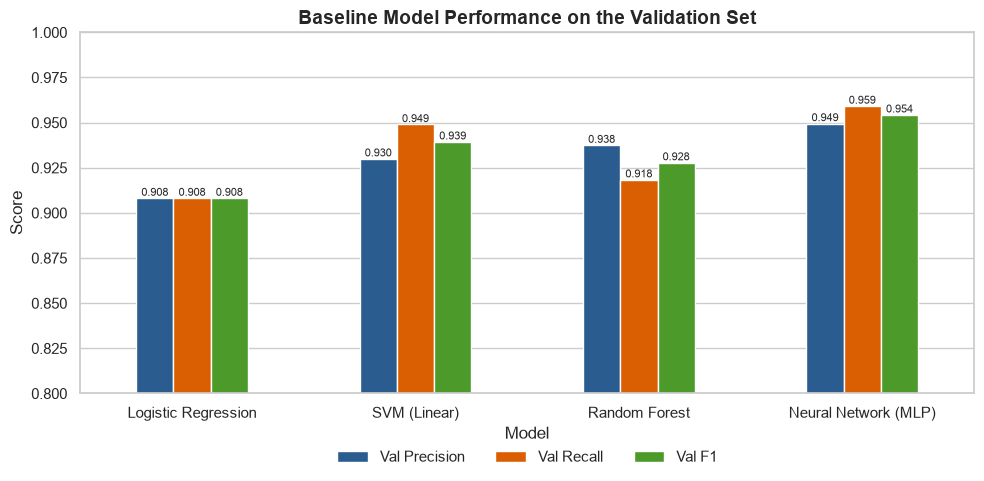

In [62]:
import matplotlib.pyplot as plt

plot_df = baseline_df[['Val Precision', 'Val Recall', 'Val F1']]
ax = plot_df.plot(kind='bar', figsize=(10, 5), color=['#2b5c8f', '#d95f02', '#4c9a2a'], rot=0)
ax.set_title('Baseline Model Performance on the Validation Set', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.8, 1.0)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

3.6 Baseline Results and Discussion:

From the table and the chart we can see that:
- All four models did much better than a model that always says "ham" (87% accuracy but 0 spam detected), so the preparation in Stages 1 and 2 worked well.
- The Neural Network had the best F1-score (0.954), and Linear SVM came second (0.939). Both had good precision and recall.
- Random Forest had the highest precision (0.966) but the lowest recall (0.867), which means it misses more spam messages than the other models.
- Logistic Regression had the lowest F1-score on both sets. Its training F1 (0.951) is lower than the other models, so it may be a bit too simple (small underfitting).
- SVM, Random Forest and the Neural Network got almost perfect scores on the training data (Random Forest got 1.0), but their validation F1 was lower by about 4 to 9 points. This shows some overfitting, and it will be handled in Stage 4 by tuning the hyperparameters (for example C for SVM, tree depth for Random Forest and early stopping for the Neural Network).

These are only the first results. The final best model will be chosen in Stage 5 using the test set.

STAGE 4

4.1 Hyperparameter Tuning for Traditional Machine Learning Models

In [63]:
from sklearn.model_selection import GridSearchCV

log_reg_grid = GridSearchCV(
    estimator=LogisticRegression(
        solver='liblinear',
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED
    ),
    param_grid={'C': [0.01, 0.5, 1, 10]},
    scoring='f1',
    cv=5,
    n_jobs=-1    
)

log_reg_grid.fit(X_train, y_train)
print("Best Parameters:", log_reg_grid.best_params_)
print("Best Cross-Validation F1:", round(log_reg_grid.best_score_, 4))

Best Parameters: {'C': 10}
Best Cross-Validation F1: 0.9329


In [64]:
from sklearn.metrics import f1_score

best_log_reg = log_reg_grid.best_estimator_

train_pred = best_log_reg.predict(X_train)
val_pred = best_log_reg.predict(X_val)

print("Training F1:", round(f1_score(y_train, train_pred), 4))
print("Validation F1:", round(f1_score(y_val, val_pred), 4))

Training F1: 0.9935
Validation F1: 0.9286


In [65]:
log_reg_c1 = LogisticRegression(
C=1,
     solver='liblinear',
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED
    )
log_reg_c1.fit(X_train, y_train)

train_pred_c1 = log_reg_c1.predict(X_train)
val_pred_c1 = log_reg_c1.predict(X_val)

print("Training F1:", round(f1_score(y_train, train_pred_c1), 4))
print("Validation F1:", round(f1_score(y_val, val_pred_c1), 4))

Training F1: 0.9507
Validation F1: 0.9082


4.1 Logistic Regression Results:

GridSearchCV selected C=10 with a cross-validation F1-score of 0.9329.

The training F1 was 0.9935, while the validation F1 was 0.9286. This difference indicates possible overfitting.

We tested C=1 to use stronger regularization. The difference got smaller, but the validation F1 went down to 0.9082.
We chose C=10 since it gave better validation performance.


In [66]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

svm_grid = GridSearchCV(
    estimator=LinearSVC(
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED
    ),
    param_grid={'C': [0.01, 0.5, 1, 10]},
    scoring='f1',
    cv=5,
    n_jobs=-1    
)

svm_grid.fit(X_train, y_train)
print("Best Parameters:", svm_grid.best_params_)
print("Best Cross-Validation F1:", round(svm_grid.best_score_, 4))

Best Parameters: {'C': 0.5}
Best Cross-Validation F1: 0.9388


In [67]:
best_svm = svm_grid.best_estimator_

svm_train_pred = best_svm.predict(X_train)
svm_val_pred = best_svm.predict(X_val)

print("Training F1:", round(f1_score(y_train, svm_train_pred), 4))
print("Validation F1:", round(f1_score(y_val, svm_val_pred), 4))

Training F1: 0.9913
Validation F1: 0.9293


In [68]:
svm_c01 = LinearSVC(
C=0.1,
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED
    )
svm_c01.fit(X_train, y_train)

svm_train_pred_c01 = svm_c01.predict(X_train)
svm_val_pred_c01 = svm_c01.predict(X_val)

print("Training F1:", round(f1_score(y_train, svm_train_pred_c01), 4))
print("Validation F1:", round(f1_score(y_val, svm_val_pred_c01), 4))

Training F1: 0.9646
Validation F1: 0.9239


4.2 SVM Results:

GridSearchCV selected C=0.5 with a cross-validation F1-score of 0.9388.

The training F1 was 0.9913, while the validation F1 was 0.9293. This difference indicates possible overfitting.
We tested C=0.1 to use stronger regularization. The difference got smaller, but the validation F1 went down to 0.9239.

We chose C=0.5 since it gave better validation performance.


In [69]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

randomf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=SEED,
        n_jobs=1
    ),
    param_grid={
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None]
        },

    scoring='f1',
    cv=5,
    n_jobs=-1    
)

randomf_grid.fit(X_train, y_train)
print("Best Parameters:", randomf_grid.best_params_)
print("Best Cross-Validation F1:", round(randomf_grid.best_score_, 4))

Best Parameters: {'max_depth': None, 'n_estimators': 200}
Best Cross-Validation F1: 0.9451


In [70]:
best_randomf = randomf_grid.best_estimator_
randomf_train_pred = best_randomf.predict(X_train)
randomf_val_pred = best_randomf.predict(X_val)

print("Training F1:", round(f1_score(y_train, randomf_train_pred ), 4))
print("Validation F1:", round(f1_score(y_val, randomf_val_pred), 4))

Training F1: 0.9989
Validation F1: 0.9278


In [71]:

randomf_depth20 = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
    )
randomf_depth20.fit(X_train, y_train)

randomf_train_pred_depth20 = randomf_depth20.predict(X_train)
randomf_val_pred_depth20 = randomf_depth20.predict(X_val)

print("Training F1:", round(f1_score(y_train, randomf_train_pred_depth20 ), 4))
print("Validation F1:", round(f1_score(y_val, randomf_val_pred_depth20), 4))

Training F1: 0.977
Validation F1: 0.9


In [72]:
randomf_depth10 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
    )
randomf_depth10.fit(X_train, y_train)

randomf_train_pred_depth10 = randomf_depth10.predict(X_train)
randomf_val_pred_depth10 = randomf_depth10.predict(X_val)

print("Training F1:", round(f1_score(y_train, randomf_train_pred_depth10 ), 4))
print("Validation F1:", round(f1_score(y_val, randomf_val_pred_depth10), 4))

Training F1: 0.9046
Validation F1: 0.8381


4.3 Random Forest Results:

GridSearchCV chose max_depth=None and n_estimators=200.

The best cross-validation F1-score was 0.9451.

The training F1 was 0.9989, while the validation F1 was 0.9278. This difference indicates possible overfitting.

We tested max_depth=20 to reduce overfitting. However, the validation F1 went down to 0.9000.

We also tested max_depth=10, but the validation F1 went down to 0.8381, indicating possible underfitting.

We chose max_depth=None and n_estimators=200 since they gave better validation performance.

4.4 Neural Network Hyperparameter Tuning 

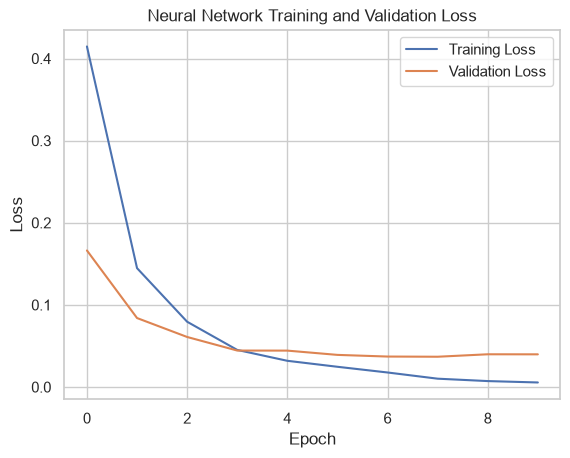

In [73]:
import matplotlib.pyplot as plt

plt.plot(history_nn.history['loss'], label='Training Loss')
plt.plot(history_nn.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Neural Network Training and Validation Loss')
plt.legend()
plt.show()

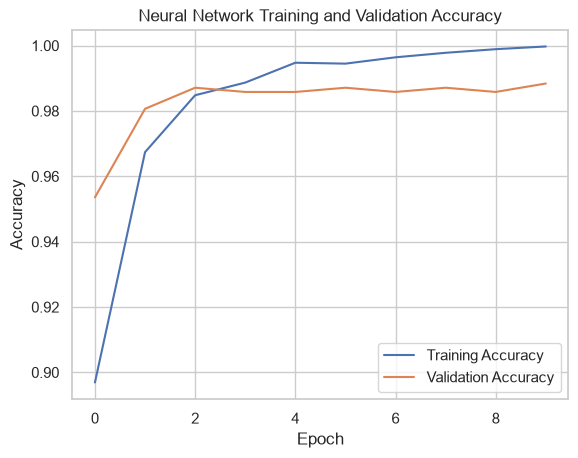

In [74]:
plt.plot(history_nn.history['accuracy'], label='Training Accuracy')
plt.plot(history_nn.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Neural Network Training and Validation Accuracy')
plt.legend()
plt.show()

In [75]:
import numpy as np
best_epoch = np.argmin(history_nn.history['val_loss']) + 1

print("Best Epoch:", best_epoch)
print("Lowest Validation Loss:", min(history_nn.history['val_loss']))

Best Epoch: 8
Lowest Validation Loss: 0.03685423731803894


In [76]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [77]:
import tensorflow as tf
nn_tuned = tf.keras.models.clone_model(nn_model)

nn_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy','precision', 'recall']
)

In [78]:
history_nn_tuned = nn_tuned.fit(
    X_train_dense,
    y_train,
    validation_data=(X_val_dense, y_val),
    epochs=20,
    batch_size=32,
    class_weight=nn_class_weight,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8776 - loss: 0.4067 - precision: 0.5088 - recall: 0.8862 - val_accuracy: 0.9613 - val_loss: 0.1573 - val_precision: 0.8091 - val_recall: 0.9082
Epoch 2/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9754 - loss: 0.1382 - precision: 0.8817 - recall: 0.9300 - val_accuracy: 0.9729 - val_loss: 0.0895 - val_precision: 0.8532 - val_recall: 0.9490
Epoch 3/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9854 - loss: 0.0724 - precision: 0.9191 - recall: 0.9694 - val_accuracy: 0.9858 - val_loss: 0.0530 - val_precision: 0.9307 - val_recall: 0.9592
Epoch 4/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9900 - loss: 0.0506 - precision: 0.9469 - recall: 0.9759 - val_accuracy: 0.9858 - val_loss: 0.0479 - val_precision: 0.9307 - val_recall: 0.9592
Epoch 5/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9942 - loss: 0.0309 - precision: 0.9678 - recall: 0.9869 - val_accuracy: 0.9884 - val_loss: 

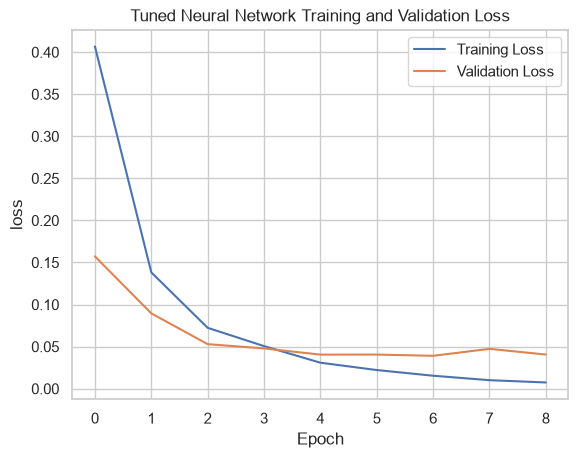

In [79]:
plt.plot(history_nn_tuned.history['loss'], label='Training Loss')
plt.plot(history_nn_tuned.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.title('Tuned Neural Network Training and Validation Loss')
plt.legend()
plt.show()

In [80]:
from sklearn.metrics import f1_score
y_pred_original = (nn_model.predict(X_val) >= 0.5).astype(int).ravel()
y_pred_tuned = (nn_tuned.predict(X_val) >= 0.5).astype(int).ravel()

f1_original = f1_score(y_val, y_pred_original)
f1_tuned = f1_score(y_val, y_pred_tuned)

print("Original NN Validation F1:", round(f1_original, 4))
print("Tuned NN Validation F1:", round(f1_tuned, 4))

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Original NN Validation F1: 0.9543
Tuned NN Validation F1: 0.9543


4.4.1 Neural Network results:

The Neural Network was trained with the Adam optimizer using a learning rate set to 0.001 and a batch size of 32. We applied Early Stopping to track the validation loss and stop the training process if it didn't get better for 2 epochs.

The model stopped training after 9 epochs rather than 20. The smallest validation loss was 0.0391 at epoch 7. As a result, the model went back to the best model weights.

The training loss continued decreasing, but the validation loss began to shift a little. This suggests possible slight overfitting. We used Early Stopping to prevent unneeded model training.

The original Neural Network had a validation F1-score of 0.9543, while the tuned Neural Network had 0.9543. Both models showed the same performance based on validation F1-score of 0.9543. Early Stopping was used to reduce unnecessary training and restore the best model weights.